# Transformer Experiment
- **Group Name**: MVPs
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
- **Owner:** Abhi Patel
---


Transformer encoder trained from scratch on the shared Enron partitions, 3 seeds, plus one ablation (positions removed).
Every configuration is chosen on the validation split. The test split is scored once, in Section 7, for the frozen final models.

## 1. Initial Configuration


### 1.1. Imports, Paths, and Device


In [5]:
# Import required libraries
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn

# Locate the repository from either its root or the notebooks folder
current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir if (current_dir / 'src').is_dir() else current_dir.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise FileNotFoundError('Place this notebook in the repository notebooks folder.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import shared project modules
from src.config import BATCH_SIZE, TRAINING_SEEDS
from src.data import load_prepared_data
from src.reproducibility import set_seed
from src.text import EncodedTextDataset, make_data_loader

# Use CUDA when it is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Print the runtime and selected device
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Python: 3.13.16
Interpreter: /usr/bin/python3
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


### 1.2. Experiment Configuration


In [6]:
##### Name this experiment and its owner
MODEL_NAME = 'transformer'
OWNER = 'Abhi Patel'

# Reset randomness before the first run
set_seed(TRAINING_SEEDS[0])

# Point to the shared prepared data and this model's output folders
PREPARED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'enron'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'enron' / MODEL_NAME
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints' / 'enron' / MODEL_NAME

# Show the shared training seeds and batch size
print('Training seeds:', TRAINING_SEEDS)
print('Batch size:', BATCH_SIZE)

Training seeds: (42, 123, 2026)
Batch size: 64


### 2. Load Shared Prepared Data


In [7]:
###### Load the saved splits, vocabulary, and metadata
prepared = load_prepared_data(PREPARED_DATA_DIR)

# Keep the cleaned partitions
splits = prepared['splits']

# Keep the training vocabulary
vocabulary = prepared['vocabulary']

# Keep the preprocessing configuration
metadata = prepared['metadata']

# Use the saved sequence length instead of choosing a new one
MAX_LENGTH = metadata['max_length']

# Confirm the vocabulary size and reserved token IDs
assert len(vocabulary) == metadata['vocabulary_size']
assert vocabulary['<pad>'] == 0 and vocabulary['<unk>'] == 1
# Confirm each split still has the saved number of rows
for name, expected_size in metadata['split_sizes'].items():
    assert len(splits[name]) == expected_size

# Show the loaded split sizes
pd.DataFrame([{'split': name, 'rows': len(part)} for name, part in splits.items()])

,split,rows
0,train,22524
1,validation,5632
2,test,1981


In [8]:
# Print dataset information
print('Vocabulary size:', len(vocabulary))
print('Maximum length:', MAX_LENGTH)
print('Dataset:', metadata['dataset_id'])
print('Dataset revision:', metadata['dataset_revision'])

Vocabulary size: 10000
Maximum length: 256
Dataset: SetFit/enron_spam
Dataset revision: main


### 2.1. Encode Development Partitions


Only training and validation are encoded. Recreate the training loader for each seed; keep validation order fixed.


In [9]:
# Encode train and validation only
encoded_datasets = {
    name: EncodedTextDataset(
        texts = splits[name]['text'],
        labels = splits[name]['label'],
        vocabulary = vocabulary,
        max_length = MAX_LENGTH) for name in ('train', 'validation')
    }

# Keep validation order fixed
validation_loader = make_data_loader(encoded_datasets['validation'], batch_size = BATCH_SIZE, shuffle = False, seed = TRAINING_SEEDS[0])

# Inspect one validation batch
example_batch = next(iter(validation_loader))
for name, tensor in example_batch.items():
    print(name, tuple(tensor.shape))

# Recreate the training loader inside every seeded run, before training.
# Do not encode or evaluate the test partition during development.

tokens (64, 256)
lengths (64,)
labels (64,)


## 3. Model, Settings, and Ablation

In [10]:
# Model code lives in src/transformer_model.py (written for this project, trained from scratch)
from src.transformer_model import (TransformerClassifier, build_model, count_parameters, evaluate,
                                   train_one_run, load_checkpoint, measure_cost, hardware_description)

VOCAB_SIZE = len(vocabulary)

# Architecture (same for every variant except the one ablated component)
MODEL_CONFIG = dict(embed_dim = 64, num_heads = 4, num_layers = 2, ff_dim = 128, dropout = 0.1)

# Training budget. CHECK: these must equal the baseline, CNN and LSTM settings (same optimizer family, same budget).
TRAIN_CONFIG = dict(epochs = 10, lr = 1e-3, weight_decay = 1e-2, grad_clip = 1.0, batch_size = BATCH_SIZE)

# One ablation: remove positional information. Everything else is held fixed.
VARIANTS = {
    'Transformer (full)': dict(use_positions = True),
    'Ablation: no positions': dict(use_positions = False),
}
VARIANT_SLUG = {name: name.lower().replace(' ', '_').replace(':', '').replace('(', '').replace(')', '') for name in VARIANTS}

print('Model config:', MODEL_CONFIG)
print('Train config:', TRAIN_CONFIG)
print('Hardware:', hardware_description(device))

Model config: {'embed_dim': 64, 'num_heads': 4, 'num_layers': 2, 'ff_dim': 128, 'dropout': 0.1}
Train config: {'epochs': 10, 'lr': 0.001, 'weight_decay': 0.01, 'grad_clip': 1.0, 'batch_size': 64}
Hardware: GPU: Tesla T4


In [11]:
# Parameter counts (compare with the baseline, CNN and LSTM: they should be within about 2x, or the gap explained)
pd.DataFrame({name: {'parameters': count_parameters(build_model(VOCAB_SIZE, MAX_LENGTH, MODEL_CONFIG, cfg))}
              for name, cfg in VARIANTS.items()}).T

,parameters
Transformer (full),723586
Ablation: no positions,707202


## 4. Train on Training Data, Select on Validation Data

Each variant is trained with each seed. The epoch with the best validation F1 is kept for every run. The test split is not used here.

In [12]:
RESULTS_DIR.mkdir(parents = True, exist_ok = True)
CHECKPOINT_DIR.mkdir(parents = True, exist_ok = True)

validation_rows, histories = [], {}
for variant, variant_config in VARIANTS.items():
    for seed in TRAINING_SEEDS:
        checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{seed}.pt'
        model, history, best_epoch, seconds = train_one_run(
            MODEL_CONFIG, variant_config, seed, encoded_datasets['train'], validation_loader,
            VOCAB_SIZE, MAX_LENGTH, device, TRAIN_CONFIG, checkpoint)
        best = history.loc[history['epoch'] == best_epoch].iloc[0]
        histories[(variant, seed)] = history
        validation_rows.append({'variant': variant, 'seed': seed, 'best_epoch': best_epoch,
                                'val_accuracy': best['val_accuracy'], 'val_f1': best['val_f1'],
                                'val_loss': best['val_loss'], 'train_seconds': round(seconds, 1)})
        print(f'{variant:24s} seed {seed:5d}  best epoch {best_epoch:2d}  val acc {best["val_accuracy"]:.4f}  F1 {best["val_f1"]:.4f}  ({seconds:.0f}s)')

validation_results = pd.DataFrame(validation_rows)
validation_results.to_csv(RESULTS_DIR / 'validation_per_seed.csv', index = False)
validation_results.round(4)

Transformer (full)       seed    42  best epoch  9  val acc 0.9886  F1 0.9882  (82s)
Transformer (full)       seed   123  best epoch  8  val acc 0.9856  F1 0.9851  (82s)
Transformer (full)       seed  2026  best epoch 10  val acc 0.9860  F1 0.9854  (82s)
Ablation: no positions   seed    42  best epoch  8  val acc 0.9879  F1 0.9875  (82s)
Ablation: no positions   seed   123  best epoch 10  val acc 0.9874  F1 0.9870  (82s)
Ablation: no positions   seed  2026  best epoch 10  val acc 0.9863  F1 0.9859  (81s)


,variant,seed,best_epoch,val_accuracy,val_f1,val_loss,train_seconds
0,Transformer (full),42,9,0.9886,0.9882,0.0397,81.5
1,Transformer (full),123,8,0.9856,0.9851,0.0491,82.2
2,Transformer (full),2026,10,0.9860,0.9854,0.0639,82.1
3,Ablation: no positions,42,8,0.9879,0.9875,0.0594,81.6
4,Ablation: no positions,123,10,0.9874,0.9870,0.0591,81.8
5,Ablation: no positions,2026,10,0.9863,0.9859,0.0664,81.4


In [13]:
# Mean and spread across seeds (sample standard deviation, n = 3)
validation_summary = validation_results.groupby('variant')[['val_accuracy', 'val_f1']].agg(['mean', 'std'])
validation_summary.round(4)

val_accuracy          val_f1        
                               mean     std    mean     std
variant                                                    
Ablation: no positions       0.9872  0.0008  0.9868  0.0008
Transformer (full)           0.9867  0.0016  0.9862  0.0017

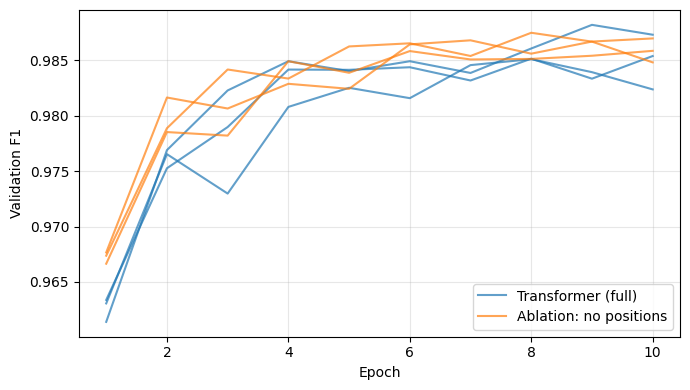

In [14]:
# Validation F1 per epoch for every run (training curves)
fig, ax = plt.subplots(figsize = (7, 4))
colors = {name: color for name, color in zip(VARIANTS, ['tab:blue', 'tab:orange'])}
for (variant, seed), history in histories.items():
    ax.plot(history['epoch'], history['val_f1'], color = colors[variant], alpha = 0.7,
            label = variant if seed == TRAINING_SEEDS[0] else None)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation F1'); ax.legend(); ax.grid(alpha = 0.3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / 'validation_curves.png', dpi = 150)
plt.show()

In [15]:
# Paired difference per seed: ablation minus full model (validation F1)
pivot = validation_results.pivot(index = 'seed', columns = 'variant', values = 'val_f1')
pivot['difference (ablation - full)'] = pivot['Ablation: no positions'] - pivot['Transformer (full)']
display(pivot.round(4))
print('Mean difference: %.4f | spread of the full model across seeds (std): %.4f' %
      (pivot['difference (ablation - full)'].mean(), pivot['Transformer (full)'].std()))

variant,Ablation: no positions,Transformer (full),difference (ablation - full)
seed,,,
42,0.9875,0.9882,-0.0007
123,0.9870,0.9851,0.0019
2026,0.9859,0.9854,0.0005


Mean difference: 0.0005 | spread of the full model across seeds (std): 0.0017


## 5. Inference Cost

Measured on the validation split, so the test split stays untouched. Timing uses seed-42 weights; the architecture is identical across seeds.

In [16]:
cost_rows = []
for variant, variant_config in VARIANTS.items():
    checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{TRAINING_SEEDS[0]}.pt'
    model = load_checkpoint(checkpoint, VOCAB_SIZE, MAX_LENGTH, MODEL_CONFIG, variant_config, device)
    cost_rows.append({'variant': variant, **measure_cost(model, encoded_datasets['validation'], device, batch_size = BATCH_SIZE)})
cost_results = pd.DataFrame(cost_rows)
cost_results.to_csv(RESULTS_DIR / 'inference_cost.csv', index = False)
cost_results.round(3)

,variant,parameters,ms_per_sample_batch1_mean,ms_per_sample_batch1_median,ms_per_sample_batch64,peak_memory_mb,memory_measure,samples_timed,hardware
0,Transformer (full),723586,1.488,1.313,0.144,181.085,CUDA peak allocated (includes weights),300,GPU: Tesla T4
1,Ablation: no positions,707202,3.099,1.913,0.136,181.857,CUDA peak allocated (includes weights),300,GPU: Tesla T4


## 6. Freeze Before Testing

Stop here and confirm with the group: the settings in Section 3 match the other models, and nothing will change after the test result is seen.
Changing a model after looking at test performance would make the test result an optimistic estimate.

## 7. Final Test Evaluation (run once)

In [17]:
TEST_FILE = RESULTS_DIR / 'test_per_seed.csv'
ALLOW_TEST_RERUN = False   # leave False: the test split is scored once
if TEST_FILE.exists() and not ALLOW_TEST_RERUN:
    raise RuntimeError('Test results already exist. The test split is scored once; do not rerun after seeing it.')

# Encode the test partition here and nowhere else
test_dataset = EncodedTextDataset(texts = splits['test']['text'], labels = splits['test']['label'],
                                  vocabulary = vocabulary, max_length = MAX_LENGTH)
test_loader = make_data_loader(test_dataset, batch_size = BATCH_SIZE, shuffle = False, seed = TRAINING_SEEDS[0])

test_rows = []
for variant, variant_config in VARIANTS.items():
    for seed in TRAINING_SEEDS:
        checkpoint = CHECKPOINT_DIR / f'{VARIANT_SLUG[variant]}_seed{seed}.pt'
        model = load_checkpoint(checkpoint, VOCAB_SIZE, MAX_LENGTH, MODEL_CONFIG, variant_config, device)
        result = evaluate(model, test_loader, device)
        test_rows.append({'variant': variant, 'seed': seed, 'test_accuracy': result['accuracy'], 'test_f1': result['f1']})

test_results = pd.DataFrame(test_rows)
test_results.to_csv(TEST_FILE, index = False)
test_results.round(4)

,variant,seed,test_accuracy,test_f1
0,Transformer (full),42,0.9849,0.9849
1,Transformer (full),123,0.9859,0.9859
2,Transformer (full),2026,0.9869,0.9868
3,Ablation: no positions,42,0.9884,0.9885
4,Ablation: no positions,123,0.9859,0.9860
5,Ablation: no positions,2026,0.9904,0.9905


In [18]:
# Final table for the report: every seed, mean and spread
test_summary = test_results.groupby('variant')[['test_accuracy', 'test_f1']].agg(['mean', 'std'])
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv')
test_summary.round(4)

test_accuracy         test_f1        
                                mean     std    mean     std
variant                                                     
Ablation: no positions        0.9882  0.0023  0.9883  0.0022
Transformer (full)            0.9859  0.0010  0.9859  0.0010